# 07 — Cut-off strategy

A score on its own doesn't make a decision. The bank has to choose **where to draw the line**. A cut-off means: customers scoring
at or above it are approved, those below are declined. In a behavioural scorecard, which scores *existing* customers,
"decline" stands for actions like blocking further spending, cutting the limit or not renewing the card.

Every cut-off is a trade-off:
- a **low cut-off** keeps more customers (more revenue) but lets more bads through (more losses);
- a **high cut-off** avoids losses but turns away good customers, and their revenue.

We look at it three ways: the **strategy table** (what each cut-off does), **expected profit** (what it is worth) and a
**three-zone policy** (decline / refer / approve). All numbers are on the **test set**: 9,000 customers the scorecard has never seen.

Run notebooks 02–06 first.

In [1]:
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scorecard.binning import load_binnings
from scorecard.data import MODELS_DIR, PROCESSED_DIR, REPORTS_DIR
from scorecard.plots import plot_profit_curve, plot_strategy_curves
from scorecard.scaling import pd_to_score, scaling_constants, score_customers
from scorecard.strategy import (
    APPROVE_FROM,
    DECLINE_BELOW,
    ProfitAssumptions,
    average_balance,
    best_cutoff,
    break_even_pd,
    expected_profit,
    profit_by_zone,
    strategy_table,
    zone_summary,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)

scorecard = pd.read_csv(REPORTS_DIR / "scorecard.csv")
binnings = load_binnings(MODELS_DIR / "binnings.pkl")
test = pd.read_csv(PROCESSED_DIR / "test.csv")
scores = score_customers(test, scorecard, binnings)
defaults = test["default"]
balances = average_balance(test)
performance = pd.read_csv(REPORTS_DIR / "performance.csv").set_index("sample")
KS_SCORE = performance.loc["Test", "ks_score"]
factor, offset = scaling_constants()
RATE = "{:.1%}"

## 1. Strategy table

For each cut-off from 460 to 600:
- **approval rate:** share of customers approved;
- **bad rate among approved:** how risky the customers we keep are;
- **bad rate among declined:** how risky the customers we turn away are;
- **% of all bads declined:** how many of the eventual defaulters the cut-off stops;
- **% of all goods declined:** the price paid, in good customers turned away.

In [2]:
table = strategy_table(scores, defaults, list(range(460, 601, 10)))
table.to_csv(REPORTS_DIR / "strategy_table.csv", index=False)
table.style.format({"cutoff": "{:.0f}", "approved": "{:,}", "approval_rate": "{:.1%}",
                    "approved_bad_rate": "{:.1%}", "declined_bad_rate": "{:.1%}",
                    "bads_declined_share": "{:.1%}", "goods_declined_share": "{:.1%}"}, na_rep="n/a")

,cutoff,approved,approval_rate,approved_bad_rate,declined_bad_rate,bads_declined_share,goods_declined_share
0,460,"8,660",96.2%,20.0%,75.0%,12.8%,1.2%
1,470,"8,412",93.5%,18.6%,72.3%,21.3%,2.3%
2,480,"8,114",90.2%,17.1%,68.3%,30.4%,4.0%
3,490,"7,874",87.5%,16.1%,64.6%,36.5%,5.7%
4,500,"7,571",84.1%,15.1%,59.5%,42.7%,8.3%
5,510,"7,130",79.2%,14.0%,53.3%,50.0%,12.5%
6,520,"6,506",72.3%,12.6%,47.0%,58.8%,18.9%
7,530,"5,988",66.5%,12.1%,42.0%,63.5%,24.9%
8,540,"4,865",54.1%,10.8%,35.4%,73.5%,38.1%
9,550,"2,544",28.3%,7.7%,27.8%,90.2%,66.5%


- **Cut-offs from 580 up decline everyone.** The highest test score is 575, so above that there's nobody left to approve
  (shown as n/a). The 600 anchor of the scale is far above this portfolio's scores, as noted in Step 6.
- **Between 540 and 550 the table changes sharply:** the approval rate falls from 54% to 28%. About a quarter of all customers score
  540–549. They are the "revolving, never late" majority, so any cut-off in that range swings a lot of customers at once.
- **At 520,** close to the KS score of 517, the bank keeps **72%** of customers, stops **59%** of bads, and turns away **19%** of goods.

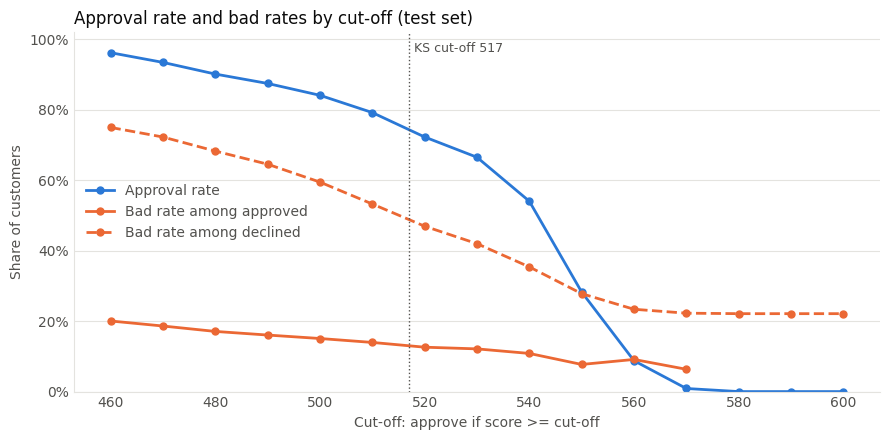

In [3]:
plot_strategy_curves(table, ks_score=KS_SCORE)
plt.show()

The two bad-rate lines show the trade-off. Raising the cut-off makes the approved book safer (solid orange line falls), but the
customers being declined become less and less risky (dashed orange line falls too). At high cut-offs we are mostly turning away goods.

## 2. Expected profit

To put a value on each cut-off we need two business assumptions. They are **clearly assumptions**, configurable in
`ProfitAssumptions`, and should be replaced by the bank's real figures:

| Assumption | Value | Meaning |
|---|---|---|
| Margin on a good customer | **8%** of their average balance per year | interest and fees, minus funding and running costs |
| Loss given default (LGD) | **60%** of a bad customer's average balance | what's lost after collections and recoveries |

The **average balance** is the mean of the six monthly bills. A negative balance (the bank owes the customer) counts as zero.
Declined customers earn and lose nothing.

**Break-even point.** One bad costs 0.60 ÷ 0.08 = **7.5 times** what one good earns, so a group of customers is only profitable if
its bad rate is below 0.08 ÷ (0.08 + 0.60) = **11.8%**. The scorecard turns that PD into a score.

In [4]:
base = ProfitAssumptions(margin_rate=0.08, lgd=0.60)
logging.info("Average balance: goods NT$%.0f, bads NT$%.0f", balances[defaults == 0].mean(), balances[defaults == 1].mean())
logging.info("Break-even PD %.1f%% = score %.0f", 100 * break_even_pd(base), pd_to_score(break_even_pd(base), factor, offset))
profit = expected_profit(scores, defaults, balances, list(range(430, 581)), base)
best = best_cutoff(profit)
logging.info("Approve everyone: NT$%.1fM | Best cut-off %d: NT$%.1fM, approval %.1f%%",
             profit["profit"].iloc[0] / 1e6, best["cutoff"], best["profit"] / 1e6, 100 * best["approval_rate"])

INFO root: Average balance: goods NT$45099, bads NT$44754


INFO root: Break-even PD 11.8% = score 545


INFO root: Approve everyone: NT$-28.2M | Best cut-off 547: NT$2.0M, approval 35.6%


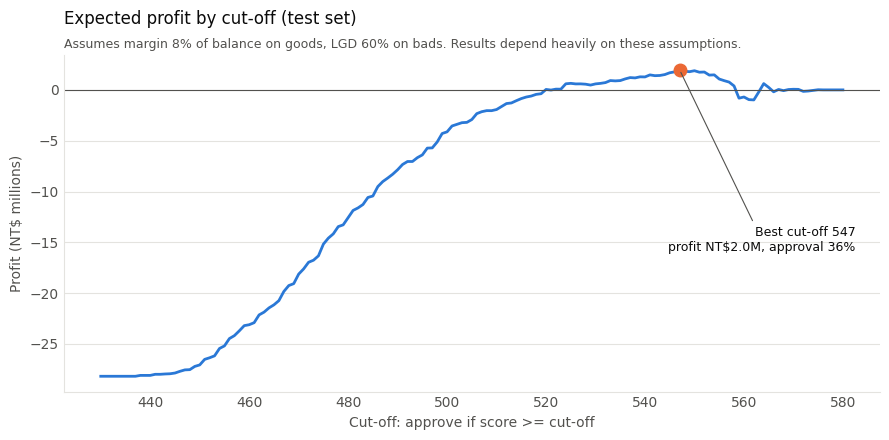

In [5]:
plot_profit_curve(profit, best, "Assumes margin 8% of balance on goods, LGD 60% on bads. "
                                "Results depend heavily on these assumptions.")
plt.show()

- **Approving everyone loses about NT$28M.** At a 22% default rate the book is far above the 11.8% break-even.
- **Profit peaks at a cut-off of 547: about NT$2.0M, approving 36% of customers.** That's right where the break-even score lands (about 545).
- **The peak is narrow and fragile.** Profit falls quickly on both sides, and a few points either way moves thousands of customers,
  because so many share scores around 540–555.

**⚠ These results depend on the margin and LGD assumptions, and on one mismatch in particular.** The margin is a *yearly* figure,
but our `default` flag is a *one-month* outcome, in a dataset with a 22% default rate that's far higher than a real card book.
A real profit analysis would use the bank's own margin, LGD and a 12-month "bad" definition. The *shape* of the analysis carries over,
but the actual cut-off would almost certainly be lower.

## 3. Sensitivity: how much does the best cut-off depend on LGD?

In [6]:
rows = []
for lgd in [0.40, 0.60, 0.80]:
    assumptions = ProfitAssumptions(margin_rate=0.08, lgd=lgd)
    curve = expected_profit(scores, defaults, balances, list(range(430, 581)), assumptions)
    top = best_cutoff(curve)
    rows.append({"lgd": lgd, "break_even_pd": break_even_pd(assumptions),
                 "break_even_score": pd_to_score(break_even_pd(assumptions), factor, offset),
                 "best_cutoff": top["cutoff"], "approval_rate": top["approval_rate"],
                 "profit_nt_millions": top["profit"] / 1e6,
                 "profit_approve_all_nt_millions": curve["profit"].iloc[0] / 1e6})
sensitivity = pd.DataFrame(rows)
sensitivity.style.format({"lgd": "{:.0%}", "break_even_pd": RATE, "break_even_score": "{:.0f}",
                          "best_cutoff": "{:.0f}", "approval_rate": RATE, "profit_nt_millions": "{:.1f}",
                          "profit_approve_all_nt_millions": "{:.1f}"})

,lgd,break_even_pd,break_even_score,best_cutoff,approval_rate,profit_nt_millions,profit_approve_all_nt_millions
0,40%,16.7%,534,524,70.3%,7.6,-10.4
1,60%,11.8%,545,547,35.6%,2.0,-28.2
2,80%,9.1%,554,575,0.0%,0.0,-46.0


- **LGD 40%:** best cut-off **524**, approving 70%. Close to the KS score.
- **LGD 60%:** best cut-off **547**, approving 36%.
- **LGD 80%:** **no cut-off makes money.** The "best" is effectively to approve almost nobody: even the safest band (bad rate about 8–9%)
  is near the 9.1% break-even.

A 20-point change in LGD moves the best cut-off by more than 20 points and the approval rate by more than 30 percentage points.
**The cut-off can't be set responsibly until the bank pins down LGD.** That is the case for a three-zone policy.

## 4. Proposed three-zone policy

Instead of one line, two:
- **Decline** where the customer is unprofitable **whatever the LGD**;
- **Approve** where the customer is profitable **unless LGD is very high**;
- **Refer** in between, where profitability depends on the assumptions.

In [7]:
policy = zone_summary(scores, defaults, DECLINE_BELOW, APPROVE_FROM)
for lgd in [0.40, 0.60, 0.80]:
    zone_profit = profit_by_zone(scores, defaults, balances, DECLINE_BELOW, APPROVE_FROM,
                                 ProfitAssumptions(margin_rate=0.08, lgd=lgd))
    policy[f"profit_lgd{lgd:.0%}_nt_millions"] = (zone_profit / 1e6).values
policy.to_csv(REPORTS_DIR / "cutoff_policy.csv", index=False)
policy.style.format({"customers": "{:,}", "bads": "{:,}", "share": RATE, "bad_rate": RATE,
                     "share_of_all_bads": RATE, "profit_lgd40%_nt_millions": "{:+.1f}",
                     "profit_lgd60%_nt_millions": "{:+.1f}", "profit_lgd80%_nt_millions": "{:+.1f}"})

,zone,score_range,customers,bads,share,bad_rate,share_of_all_bads,profit_lgd40%_nt_millions,profit_lgd60%_nt_millions,profit_lgd80%_nt_millions
0,Decline,< 520,"2,494","1,171",27.7%,47.0%,58.8%,-17.7,-28.2,-38.7
1,Refer,520 to 549,"3,962",624,44.0%,15.7%,31.3%,+1.0,-1.8,-4.6
2,Approve,>= 550,"2,544",196,28.3%,7.7%,9.8%,+6.4,+1.9,-2.6


**Comparison with the KS cut-off (517).** KS finds the score that best *separates* goods from bads, treating a missed bad and a
lost good as equally important. The profit analysis says they're not: one bad costs 7.5 goods' margin, so it pushes the cut-off much higher (547).
The two numbers answer different questions, and the policy uses both:
- the **decline line (520)** sits at the KS point, where separation is greatest and the declined group defaults at 47%;
- the **approve line (550)** sits at the profit optimum under the base assumptions.

**Practical note on the refer zone.** 44% of customers is far more than any team can review by hand. For existing customers, "refer"
should mean an **automatic hold**: keep the account open but give no limit increases, monitor more closely and contact earlier in collections.
Manual review should be reserved for the highest balances. The size of this zone is itself a finding: the bank's uncertainty about LGD
translates directly into 44% of customers whose treatment can't yet be decided on economics alone.

### Rationale for the credit committee

> We propose a three-zone policy on the behavioural score. **Below 520**, customers (28% of the book) default at 47% and hold 59% of all
> defaulters. They lose money under every loss assumption we tested, so new credit is declined. **From 550**, customers (28%) default at 7.7%
> and are profitable unless losses on default exceed about 70% of balance; they are approved automatically. **Between 520 and 549** (44%),
> the default rate is 15.7%, and whether these customers are profitable depends on our loss-given-default assumption: positive at 40%,
> negative at 60% and above. These accounts are held at their current terms and monitored, not grown. The thresholds should be
> recalibrated once finance confirms the margin and LGD, and once a 12-month default definition is available. They should then be
> reviewed quarterly against actual outcomes.